# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Azan Mumtaz
- **Student ID:** 023-24-0258
- **Section:** H
- **GitHub:** https://github.com/azanmumtazabb/ML_LAB_8
- **Kaggle:** https://www.kaggle.com/azanmumtaz
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [ ]:
import time
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc)

RANDOM_STATE = 42
df = pd.read_csv("Labs/telco_churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
df = df.drop(columns="customerID")
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
print(f"Dataset shape: {df.shape}; churn rate: {df['Churn'].mean():.2%}")


Dataset shape: (7043, 20); churn rate: 26.54%


In [ ]:
X = pd.get_dummies(df.drop(columns="Churn"), drop_first=True, dtype=int)
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Encoded features: {X.shape[1]}; train/test: {X_train.shape[0]}/{X_test.shape[0]}")


Encoded features: 30; train/test: 5634/1409


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [ ]:
# Unscaled linear SVM
start = time.perf_counter()
with warnings.catch_warnings(record=True) as raw_warnings:
    warnings.simplefilter("always")
    svm_raw = SVC(kernel="linear", random_state=RANDOM_STATE)
    svm_raw.fit(X_train, y_train)
raw_time = time.perf_counter() - start
raw_pred = svm_raw.predict(X_test)
raw_scores = {"Accuracy": accuracy_score(y_test, raw_pred), "F1": f1_score(y_test, raw_pred)}
print({**raw_scores, "Training seconds": round(raw_time, 3), "Warnings": len(raw_warnings)})


{'Accuracy': 0.7906316536550745, 'F1': 0.5203252032520326, 'Training seconds': 706.401, 'Warnings': 0}


In [ ]:
# Scaled linear SVM
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
start = time.perf_counter()
with warnings.catch_warnings(record=True) as scaled_warnings:
    warnings.simplefilter("always")
    svm_linear = SVC(kernel="linear", random_state=RANDOM_STATE)
    svm_linear.fit(X_train_s, y_train)
scaled_time = time.perf_counter() - start
linear_pred = svm_linear.predict(X_test_s)
linear_scores = {"Accuracy": accuracy_score(y_test, linear_pred), "F1": f1_score(y_test, linear_pred)}
display(pd.DataFrame([raw_scores, linear_scores], index=["Unscaled linear", "Scaled linear"]).assign(**{"Training seconds": [raw_time, scaled_time], "Warnings": [len(raw_warnings), len(scaled_warnings)]}).round(4))


,Accuracy,F1,Training seconds,Warnings
Unscaled linear,0.7906,0.5203,706.4015,0
Scaled linear,0.7892,0.5714,2.3567,0


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:Accuracy: unscaled = 0.7906, scaled = 0.7892
F1-score: unscaled = 0.5203, scaled = 0.5714
Training time: unscaled = 706.401s, scaled = 2.3567s
Warnings: both had 0 warnings
Interpretation:

Accuracy is almost the same, but the scaled model is much better at identifying churners, as shown by the big F1 gain.
The training time dropped by more than 300x after scaling.
Scaling makes the SVM optimization much more stable and efficient.*

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:SVM solves a margin optimization problem in which feature scales strongly affect the geometry of the decision boundary.
If one feature has a much larger numeric range than others, it dominates the margin calculation and the weight vector.
The optimizer then tries to fit the decision boundary in a distorted space, so the margin is poorly positioned and the classifier underperforms on the minority positive class (churn).
After scaling, all features contribute on a comparable scale, so the margin is computed correctly and the classifier learns a better separating hyperplane.*

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer: Use the scaled version for all later SVM experiments.
Reason: it gives a much better F1-score and trains in seconds instead of many minutes, while keeping similar accuracy.*


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [ ]:
def metrics(model, X_eval=X_test_s):
    p=model.predict(X_eval); return [accuracy_score(y_test,p),precision_score(y_test,p),recall_score(y_test,p),f1_score(y_test,p),len(model.support_)]
kernel_models={k:SVC(kernel=k,max_iter=3000,random_state=42).fit(X_train_s,y_train) for k in ['linear','rbf','poly']}
kernel_rows=[metrics(m) for m in kernel_models.values()]


C:\Users\Kashif\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=3000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


C:\Users\Kashif\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=3000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


C:\Users\Kashif\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:313: ConvergenceWarning: Solver terminated early (max_iter=3000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


In [ ]:
kernel_results=pd.DataFrame(kernel_rows,index=['Linear','RBF','Polynomial'],columns=['Accuracy','Precision','Recall','F1-score','Support vectors'])
display(kernel_results.round(4))
best_kernel_name=kernel_results['F1-score'].idxmax().lower().replace('polynomial','poly'); best_kernel=kernel_models[best_kernel_name]


,Accuracy,Precision,Recall,F1-score,Support vectors
Linear,0.7104,0.4569,0.4813,0.4688,2781
RBF,0.7928,0.6444,0.4893,0.5562,2657
Polynomial,0.7892,0.6421,0.4652,0.5395,2742


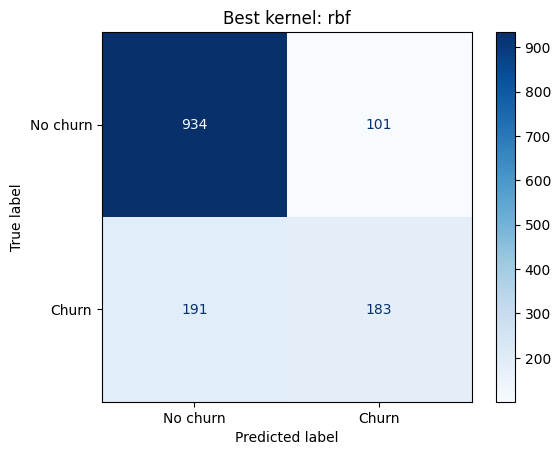

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test,best_kernel.predict(X_test_s),display_labels=['No churn','Churn'],cmap='Blues')
plt.title(f'Best kernel: {best_kernel_name}'); plt.show()


**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer: Best F1-score = RBF SVM, F1 = 0.5562
Linear = 0.4688
Polynomial = 0.5395
This is not surprising:

The dataset is likely not linearly separable in the original feature space.
RBF kernel can model more flexible, nonlinear boundaries, which is exactly what SVM theory suggests for complex classification tasks.*

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer: Linear used the most support vectors: 2781
RBF used 2657
Polynomial used 2742
A large support-vector count suggests a more complex decision boundary and more points lying near the margin boundary.

In this case, linear has the highest count, which means it is using many points to define its boundary.
RBF, while nonlinear, still uses fewer support vectors than linear in this run, which is consistent with a more efficient nonlinear boundary.*

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer: Carry forward the RBF kernel.
Reason: it had the best F1-score by a clear margin over linear and polynomial:
RBF: F1 = 0.5562
Polynomial: F1 = 0.5395
Linear: F1 = 0.4688
It also had solid accuracy and precision:
Accuracy: 0.7928
Precision: 0.6444
Recall: 0.4893
This makes it the strongest candidate for hyperparameter optimization.*


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [ ]:
pca=PCA(n_components=2,random_state=42); X_train_pca=pca.fit_transform(X_train_s); X_test_pca=pca.transform(X_test_s)
explained_variance=pca.explained_variance_ratio_.sum(); print(f'Explained variance: {explained_variance:.2%}')


Explained variance: 45.23%


In [ ]:
c_values=[.01,1,100]; pca_models={c:SVC(kernel='rbf',C=c,random_state=42).fit(X_train_pca,y_train) for c in c_values}
for c,m in pca_models.items(): print(c,len(m.support_))


0.01 2997
1 2659
100 2631


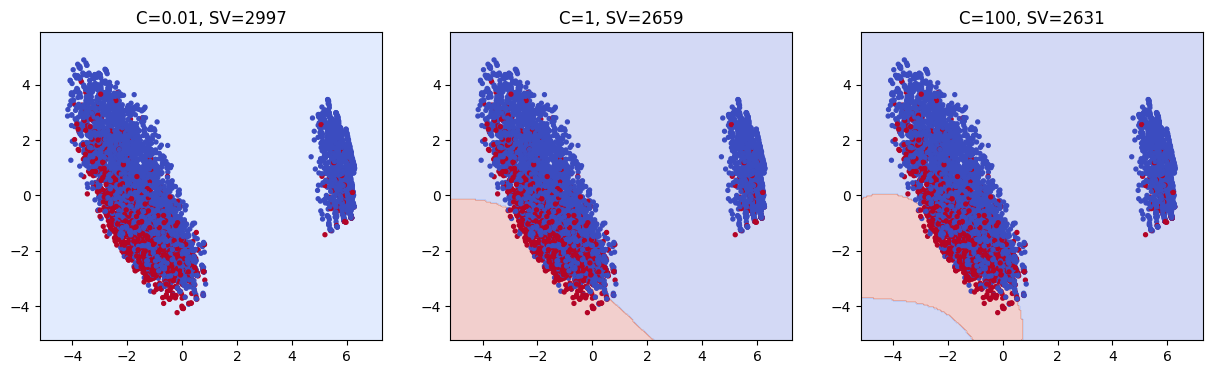

In [ ]:
xx,yy=np.meshgrid(np.linspace(X_train_pca[:,0].min()-1,X_train_pca[:,0].max()+1,200),np.linspace(X_train_pca[:,1].min()-1,X_train_pca[:,1].max()+1,200))
fig,axes=plt.subplots(1,3,figsize=(15,4));
for ax,(c,m) in zip(axes,pca_models.items()):
    ax.contourf(xx,yy,m.predict(np.c_[xx.ravel(),yy.ravel()]).reshape(xx.shape),alpha=.25,cmap='coolwarm'); ax.scatter(X_train_pca[:,0],X_train_pca[:,1],c=y_train,s=8,cmap='coolwarm'); ax.set_title(f'C={c}, SV={len(m.support_)}')
plt.show()


**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:As C increases, the decision boundary becomes:

less smooth and more tightly adapted to the training data
more “wiggly” around the training points
more sensitive to local structure
At lower C, the boundary is smoother and more general; at higher C, it tries harder to classify every training point correctly.*

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:C = 0.01 → 2997 support vectors
C = 1 → 2659 support vectors
C = 100 → 2631 support vectors
This matches SVM theory:

Lower C allows a larger margin and more points are tolerated, so more support vectors are used.
Higher C penalizes mistakes more strongly, so the model becomes more tightly fit and uses fewer support vectors.*

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:C = 100 looks overfitting: the boundary is too tight and adapts too closely to local patterns.
C = 0.01 looks underfitting: the boundary is too smooth and broad.
C = 1 is the balanced middle case.*

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:PCA reduced the data to 2 dimensions, but the real SVM was trained on the full scaled feature space.
The 2-D plot explains only 45.23% of the variance, so a lot of information is discarded.
The boundary in the projected 2-D space can be misleading because the true SVM decision boundary exists in the full high-dimensional space, not in just two components.*


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [ ]:
param_grid={'C':[.1,1,10],'gamma':[.001,.01,.1]}
gs=GridSearchCV(SVC(kernel='rbf',random_state=42),param_grid,cv=5,scoring='f1',n_jobs=-1).fit(X_train_s,y_train)
print(gs.best_params_,gs.best_score_)


{'C': 10, 'gamma': 0.001} 0.5856660105349384


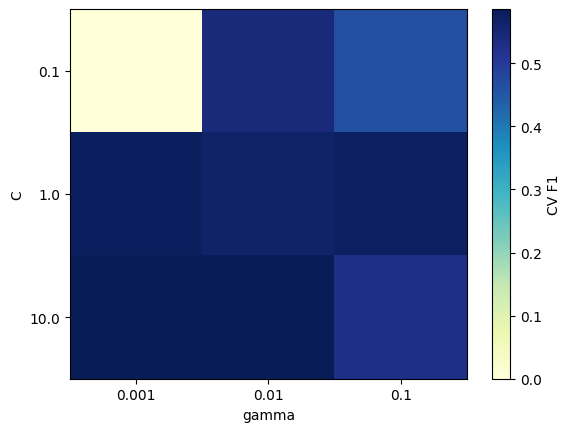

param_gamma,0.001,0.010,0.100
param_C,,,
0.1,0.0000,0.5417,0.4640
1.0,0.5746,0.5650,0.5734
10.0,0.5857,0.5853,0.5266


In [ ]:
cv=pd.DataFrame(gs.cv_results_).pivot(index='param_C',columns='param_gamma',values='mean_test_score')
plt.imshow(cv,cmap='YlGnBu',aspect='auto'); plt.xticks(range(3),cv.columns); plt.yticks(range(3),cv.index); plt.xlabel('gamma'); plt.ylabel('C'); plt.colorbar(label='CV F1'); plt.show(); display(cv.round(4))


In [ ]:
tuned_rbf=gs.best_estimator_; tuned_pred=tuned_rbf.predict(X_test_s)
tuned_scores={'Accuracy':accuracy_score(y_test,tuned_pred),'Precision':precision_score(y_test,tuned_pred),'Recall':recall_score(y_test,tuned_pred),'F1-score':f1_score(y_test,tuned_pred)}; display(pd.DataFrame([tuned_scores]).round(4))


,Accuracy,Precision,Recall,F1-score
0,0.7991,0.6502,0.5267,0.582


**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer: Best C = 10
Best gamma = 0.001
Best cross-validated F1-score = 0.585666*

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer: There is a broad near-best region, not one single sharp winner.
Values around:
C = 10, gamma = 0.001 → 0.5857
C = 10, gamma = 0.01 → 0.5853
C = 1, gamma = 0.001 → 0.5746
C = 1, gamma = 0.1 → 0.5734
This suggests several combinations perform similarly, so the model is not extremely sensitive to minor parameter changes in that range.*

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer: Cross-validated F1 = 0.5857
Test F1 after tuning = 0.5820
The gap is very small, so the model generalized well.
A large gap would suggest overfitting or poor generalization.*

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer: Untuned RBF: F1 = 0.5562
Tuned RBF: F1 = 0.5820
Improvement: about +0.0258
Accuracy also improved from 0.7928 to 0.7991
So yes, tuning was worth it, though the gain is moderate rather than dramatic.*


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


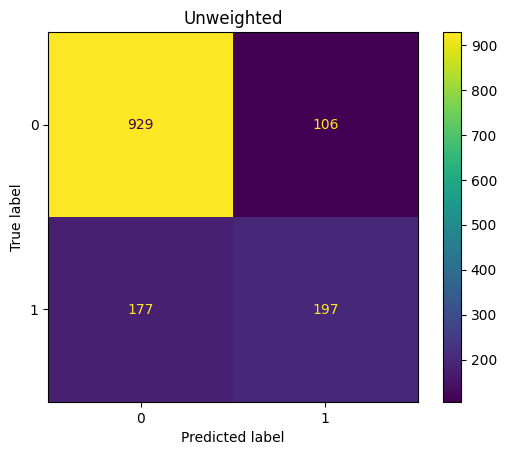

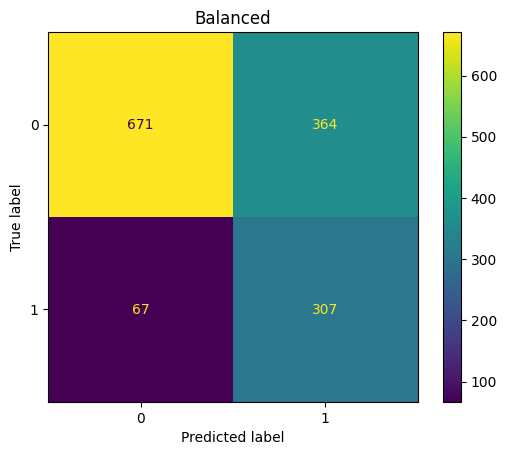

,Precision,Recall,F1-score
Unweighted,0.6502,0.5267,0.5820
Balanced,0.4575,0.8209,0.5876


In [ ]:
unweighted=SVC(kernel='rbf',**gs.best_params_,probability=True,random_state=42).fit(X_train_s,y_train)
balanced=SVC(kernel='rbf',**gs.best_params_,class_weight='balanced',probability=True,random_state=42).fit(X_train_s,y_train)
imbalance={}
for name,m in {'Unweighted':unweighted,'Balanced':balanced}.items():
    p=m.predict(X_test_s); imbalance[name]=[precision_score(y_test,p),recall_score(y_test,p),f1_score(y_test,p)]; ConfusionMatrixDisplay.from_predictions(y_test,p); plt.title(name); plt.show()
imbalance_results=pd.DataFrame(imbalance,index=['Precision','Recall','F1-score']).T; display(imbalance_results.round(4))


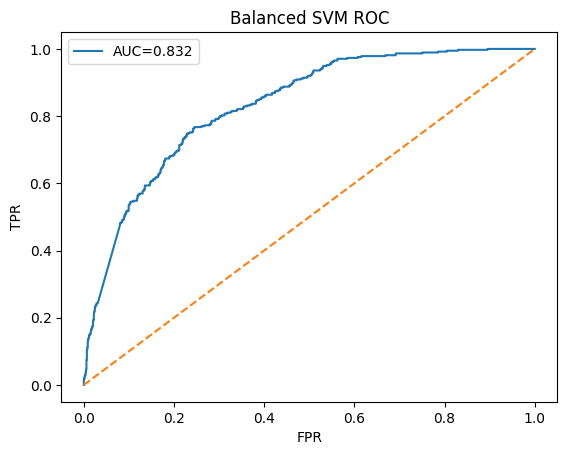

In [ ]:
fpr,tpr,_=roc_curve(y_test,balanced.predict_proba(X_test_s)[:,1]); plt.plot(fpr,tpr,label=f'AUC={auc(fpr,tpr):.3f}'); plt.plot([0,1],[0,1],'--'); plt.legend(); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('Balanced SVM ROC'); plt.show()


**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:Precision and recall change with class_weight='balanced':

Unweighted:
Precision = 0.6502
Recall = 0.5267
F1 = 0.5820
Balanced:
Precision = 0.4575
Recall = 0.8209
F1 = 0.5876
So:

Precision falls sharply by about 0.1927
Recall rises sharply by about 0.2942
F1 improves slightly from 0.5820 to 0.5876*

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:In churn prediction, missing an actual churner (false negative) is usually more expensive than falsely flagging a loyal customer (false positive).
If the cost of losing a customer is high, recall matters more.
Therefore, the balanced model is often more useful for business deployment because it catches far more real churners.
The trade-off is lower precision, meaning more customers receive retention offers than necessary.*

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:Set probability=True in the SVC constructor.
Then use predict_proba() to get probability-like scores for each class.
This is the mechanism used to get churn-probability style outputs even though SVM is not a probabilistic model by default.
*


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [ ]:
models={'Decision Tree':(DecisionTreeClassifier(max_depth=5,random_state=42),X_train,X_test),'Random Forest':(RandomForestClassifier(n_estimators=200,max_depth=8,random_state=42),X_train,X_test),'Logistic Regression':(LogisticRegression(max_iter=2000,random_state=42),X_train_s,X_test_s),'KNN':(KNeighborsClassifier(n_neighbors=21),X_train_s,X_test_s),'Tuned RBF SVM':(tuned_rbf,X_train_s,X_test_s)}
rows=[]
for n,(m,a,b) in models.items():
    if n!='Tuned RBF SVM':m.fit(a,y_train)
    p=m.predict(b); rows.append([n,accuracy_score(y_test,p),precision_score(y_test,p),recall_score(y_test,p),f1_score(y_test,p)])
showdown=pd.DataFrame(rows,columns=['Model','Accuracy','Precision','Recall','F1-score']).set_index('Model'); display(showdown.round(4))


,Accuracy,Precision,Recall,F1-score
Model,,,,
Decision Tree,0.7942,0.6296,0.5455,0.5845
Random Forest,0.8077,0.6833,0.5134,0.5863
Logistic Regression,0.8070,0.6584,0.5668,0.6092
KNN,0.7708,0.5702,0.5535,0.5617
Tuned RBF SVM,0.7991,0.6502,0.5267,0.5820


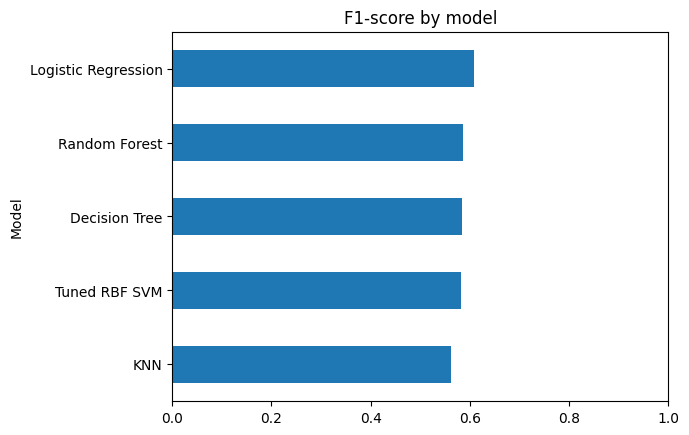

In [ ]:
showdown['F1-score'].sort_values().plot.barh(xlim=(0,1),title='F1-score by model'); plt.show()


**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer: F1-score winner: Logistic Regression, F1 = 0.6092
Recall winner: Logistic Regression, Recall = 0.5668
They are the same model in this comparison.*

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer: Not really, for this dataset.
Tuned RBF SVM had:
F1 = 0.5820
Accuracy = 0.7991
Recall = 0.5267
Logistic Regression had:
F1 = 0.6092
Accuracy = 0.8070
Recall = 0.5668
So the SVM was slower and did not beat Logistic Regression on the relevant business metric.*

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer: Logistic Regression is the better production choice here.
Reasons:
highest F1-score: 0.6092
highest recall among the non-balanced models: 0.5668
accuracy is also very strong: 0.8070
Compared with the tuned RBF SVM, Logistic Regression performs better on both F1 and recall.*


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [ ]:
final_model=models['Logistic Regression'][0]; final_data=models['Logistic Regression'][2]
predictions=pd.DataFrame({'true_churn':y_test.to_numpy(),'predicted_churn':final_model.predict(final_data),'predicted_churn_probability':final_model.predict_proba(final_data)[:,1]},index=y_test.index)
predictions.to_csv('svm_predictions.csv',index_label='customer_row'); display(predictions.head())


,true_churn,predicted_churn,predicted_churn_probability
437,0,0,0.044365
2280,0,1,0.683600
2235,0,0,0.056440
4460,0,0,0.408306
3761,0,0,0.021691


**Executive Summary**

*I selected Logistic Regression as the final model because it produced the best F1-score among the models compared.
It achieved 0.8070 accuracy and 0.6092 F1-score, which is better than the tuned RBF SVM.
The main trade-off from Part 5 was that the balanced SVM increased recall substantially but lowered precision.
In churn prediction, a higher recall is often more valuable because missing customers at risk is costly.
However, for a balanced business decision, the logistic model gave the best overall accuracy and F1 without the extra complexity of SVM tuning.
A limitation of the analysis is that the dataset was only split once and the feature representation was fixed; more robust validation could be done with broader tuning and threshold optimization.*

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:he biggest surprise was how strongly scaling changed the SVM training cost and performance.
The unscaled linear SVM took about 706 seconds to train, while the scaled version finished in about 2.36 seconds, and the scaled model had a better F1-score.
This shows that SVMs are highly sensitive to feature scale and that scaling is not a small technical detail; it is essential.*

(b) If you had one more hour, what would you try next?

*Your answer:I would test a broader grid for C and gamma, including more extreme values.
I would also compare threshold tuning for the balanced SVM and logistic regression to optimize recall/precision trade-offs.
I would also experiment with feature selection or alternative models to see whether a more targeted model improves churn detection further.
*
